# Cargar modelo y predicción gráfica con Gradio

## 1. Descripción

Este notebook carga el modelo entrenado en `01_entrenamiento.ipynb` y ofrece dos formas de predecir la raza de un perro:

1. **Predicción por carpeta**: recorre una carpeta de imágenes y clasifica cada una.
2. **Interfaz gráfica con Gradio**: permite subir una imagen desde el navegador y ver el resultado visualmente.

### Flujo de trabajo
* Importar librerías
* Definir parámetros
* Cargar el modelo guardado
* Predicción sobre carpeta de prueba
* Interfaz gráfica con Gradio

## 2. Importación de librerías

In [7]:
from keras.models import load_model    # Carga un modelo guardado en disco
from PIL import Image                  # Procesamiento de imágenes
import numpy as np
import os
import matplotlib.pyplot as plt
import gradio as gr                    # Interfaz gráfica interactiva

## 3. Parámetros de la aplicación

In [8]:
tam_imagen     = 128       # Debe coincidir con el tamaño usado en el entrenamiento
carpeta_prueba = '.\\imagenes_perros\\prueba'
ruta_modelo    = 'modelo_perros.keras'

# Orden alfabético = orden de carpetas = índices que asigna Keras
clases = ['bulldog', 'golden_retriever', 'pastor_aleman']

## 4. Cargar el modelo guardado

In [9]:
modelo = load_model(ruta_modelo)
print(f'Modelo cargado correctamente desde: {ruta_modelo}')
modelo.summary()

Modelo cargado correctamente desde: modelo_perros.keras


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │     6,422,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           771 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,550,411 (74.58 MB)

 Trainable params: 6,516,803 (24.86 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 13,033,608 (49.72 MB)

## 5. Predicción sobre carpeta de prueba

Se recorren las imágenes de la carpeta `prueba` y se clasifican una a una.

Pasos para cada imagen:
1. Abrir imagen
2. Redimensionar a 128x128
3. Convertir a array de números
4. Normalizar (dividir por 255)
5. Añadir dimensión batch
6. Predecir con el modelo
7. Obtener la clase con mayor probabilidad

In [10]:
for nombre_archivo in os.listdir(carpeta_prueba):
    ruta_imagen = os.path.join(carpeta_prueba, nombre_archivo)
    if ruta_imagen.endswith(('.jpg', '.jpeg', '.png')):
        imagen = Image.open(ruta_imagen).convert('RGB').resize((tam_imagen, tam_imagen))
        imagen = np.array(imagen) / 255
        # Añadir dimensión batch: (H, W, 3) → (1, H, W, 3)
        imagen = imagen[np.newaxis, ...]
        resultado = modelo.predict(imagen, verbose=0)
        indice = np.argmax(resultado[0])
        clase = clases[indice]
        confianza = resultado[0][indice]
        print(f'{nombre_archivo} → {clase} ({confianza:.2%})')

.jpg → golden_retriever (63.80%)
bulldog_prueba.jpg → bulldog (57.41%)
golden_retriever_prueba.jpg → golden_retriever (43.60%)
pastor_aleman_prueba.jpg → pastor_aleman (70.31%)


## 6. Visualización de predicciones con matplotlib

Muestra cada imagen junto con su predicción y el porcentaje de confianza.

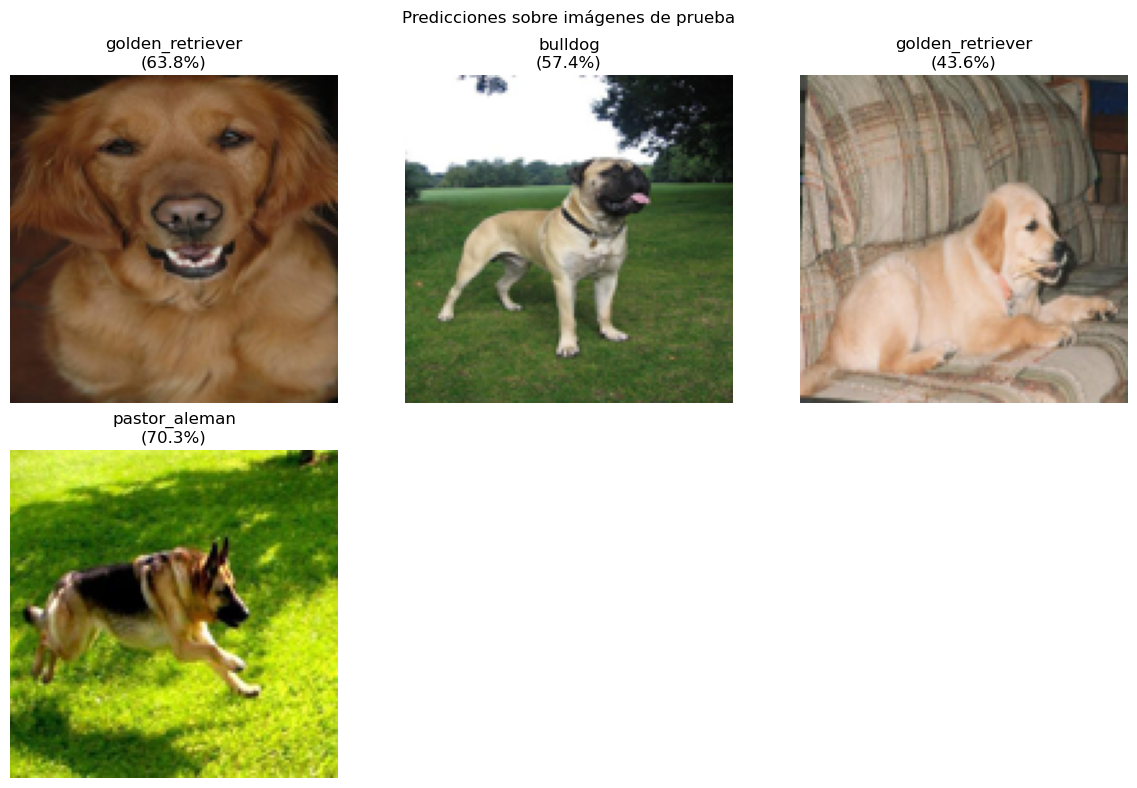

In [11]:
imagenes_prueba = [
    f for f in os.listdir(carpeta_prueba)
    if f.endswith(('.jpg', '.jpeg', '.png'))
]

cols = 3
rows = (len(imagenes_prueba) + cols - 1) // cols
plt.figure(figsize=(12, 4 * rows))

for i, nombre_archivo in enumerate(imagenes_prueba):
    ruta_imagen = os.path.join(carpeta_prueba, nombre_archivo)
    imagen = Image.open(ruta_imagen).convert('RGB').resize((tam_imagen, tam_imagen))
    img_array = np.array(imagen) / 255
    resultado = modelo.predict(img_array[np.newaxis, ...], verbose=0)
    indice = np.argmax(resultado[0])
    confianza = resultado[0][indice]

    plt.subplot(rows, cols, i + 1)
    plt.imshow(imagen)
    plt.title(f'{clases[indice]}\n({confianza:.1%})')
    plt.axis('off')

plt.suptitle('Predicciones sobre imágenes de prueba')
plt.tight_layout()
plt.show()

## 7. Interfaz gráfica con Gradio

**Gradio** permite crear una interfaz web interactiva en pocas líneas de código.

La interfaz permite:
- Subir una imagen desde el ordenador o arrastrarla
- Ver la raza predicha y las probabilidades de cada clase
- Ejecutarse en el navegador sin instalar nada adicional

Al ejecutar la celda, se generará un enlace local (y opcionalmente uno público con `share=True`) para acceder a la interfaz.

In [12]:
def predecir_raza(imagen_pil):
    """
    Recibe una imagen PIL desde Gradio, la preprocesa y devuelve
    un diccionario con la probabilidad de cada clase.
    """
    # Redimensionar y normalizar
    imagen = imagen_pil.convert('RGB').resize((tam_imagen, tam_imagen))
    img_array = np.array(imagen) / 255.0
    img_array = img_array[np.newaxis, ...].astype('float32')

    # Predecir
    resultado = modelo.predict(img_array, verbose=0)
    probabilidades = resultado[0]

    # Devolver diccionario clase → probabilidad (formato que espera Gradio)
    return {clases[i]: float(probabilidades[i]) for i in range(len(clases))}


# Crear y lanzar la interfaz Gradio
interfaz = gr.Interface(
    fn=predecir_raza,
    inputs=gr.Image(type='pil', label='Sube una imagen de un perro'),
    outputs=gr.Label(num_top_classes=3, label='Raza predicha'),
    title='Clasificador de Razas de Perros',
    description='Sube una imagen de un bulldog, golden retriever o pastor alemán para identificar su raza.',
    examples=[
        ['.\\imagenes_perros\\prueba\\bulldog_prueba.jpg'],
        ['.\\imagenes_perros\\prueba\\golden_retriever_prueba.jpg'],
        ['.\\imagenes_perros\\prueba\\pastor_aleman_prueba.jpg']
    ]
)

interfaz.launch()

* Running on local URL:  http://127.0.0.1:7861
* To create a public link, set `share=True` in `launch()`.


ERROR:    Exception in ASGI application
Traceback (most recent call last):
  File "c:\anaconda\envs\prog\Lib\site-packages\uvicorn\protocols\http\httptools_impl.py", line 416, in run_asgi
    result = await app(  # type: ignore[func-returns-value]
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\anaconda\envs\prog\Lib\site-packages\uvicorn\middleware\proxy_headers.py", line 60, in __call__
    return await self.app(scope, receive, send)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\anaconda\envs\prog\Lib\site-packages\fastapi\applications.py", line 1135, in __call__
    await super().__call__(scope, receive, send)
  File "c:\anaconda\envs\prog\Lib\site-packages\starlette\applications.py", line 113, in __call__
    await self.middleware_stack(scope, receive, send)
  File "c:\anaconda\envs\prog\Lib\site-packages\starlette\middleware\errors.py", line 186, in __call__
    raise exc
  File "c:\anaconda\envs\prog\Lib\site-packages\starlette\middleware\error